# Phase 2 — Validation on Independent Datasets

Testing how well the Phase 1 models hold up on Twitter and YouTube data they've never seen.

Two strategies:
- `text_only` — use the A1 baseline model
- `zero_shot_full` — use the A4 full model with placeholder tabular values (peerness/repetition not available in these datasets)

> Note: aggression/attack/toxicity files are excluded due to training data overlap.


In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
for candidate in [ROOT, *ROOT.parents]:
    if (candidate / "src").is_dir() and (candidate / "requirements.txt").is_file():
        ROOT = candidate
        break
else:
    raise RuntimeError("Cannot find F21MP project root.")

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.phase2_validation.evaluation.validation import run_validation

## 1. Text-only validation (A1 baseline)


In [2]:
text_only = run_validation(strategy="text_only", save_outputs=True)
text_only["summary"]

,subset,samples,positive,accuracy,precision,recall,f1,roc_auc
0,twitter_parsed_dataset.csv,16848,5347,0.684651,0.610390,0.017580,0.034176,0.512294
1,twitter_racism_parsed_dataset.csv,13471,1970,0.851088,0.285714,0.012183,0.023369,0.492103
2,twitter_sexism_parsed_dataset.csv,14878,3377,0.773693,0.538462,0.020728,0.039920,0.524072
3,youtube_parsed_dataset.csv,3464,417,0.877309,0.100000,0.002398,0.004684,0.375216


## 2. Zero-shot full model validation (A4)

Uses the saved Phase 1 full model with default tabular feature values, since these datasets don't have peerness/repetition data.


In [3]:
zero_shot_full = run_validation(strategy="zero_shot_full", save_outputs=True)
zero_shot_full["summary"]

,subset,samples,positive,accuracy,precision,recall,f1,roc_auc
0,twitter_parsed_dataset.csv,16848,5347,0.682633,0.0,0.0,0.0,0.493973
1,twitter_racism_parsed_dataset.csv,13471,1970,0.853760,0.0,0.0,0.0,0.406171
2,twitter_sexism_parsed_dataset.csv,14878,3377,0.773021,0.0,0.0,0.0,0.545192
3,youtube_parsed_dataset.csv,3464,417,0.879619,0.0,0.0,0.0,0.599143


## 3. Side-by-side comparison


In [4]:
import pandas as pd

compare = text_only["summary"][["subset", "samples", "positive", "precision", "recall", "f1", "roc_auc"]].copy()
compare = compare.rename(columns={
    "precision": "precision_text_only",
    "recall": "recall_text_only",
    "f1": "f1_text_only",
    "roc_auc": "roc_auc_text_only",
})

compare = compare.merge(
    zero_shot_full["summary"][["subset", "precision", "recall", "f1", "roc_auc"]].rename(
        columns={
            "precision": "precision_zero_shot_full",
            "recall": "recall_zero_shot_full",
            "f1": "f1_zero_shot_full",
            "roc_auc": "roc_auc_zero_shot_full",
        }
    ),
    on="subset",
)

compare

,subset,samples,positive,precision_text_only,recall_text_only,f1_text_only,roc_auc_text_only,precision_zero_shot_full,recall_zero_shot_full,f1_zero_shot_full,roc_auc_zero_shot_full
0,twitter_parsed_dataset.csv,16848,5347,0.610390,0.017580,0.034176,0.512294,0.0,0.0,0.0,0.493973
1,twitter_racism_parsed_dataset.csv,13471,1970,0.285714,0.012183,0.023369,0.492103,0.0,0.0,0.0,0.406171
2,twitter_sexism_parsed_dataset.csv,14878,3377,0.538462,0.020728,0.039920,0.524072,0.0,0.0,0.0,0.545192
3,youtube_parsed_dataset.csv,3464,417,0.100000,0.002398,0.004684,0.375216,0.0,0.0,0.0,0.599143


## 4. Interpretation

Low recall/F1 on external datasets is expected — the training domain (Wikipedia talk pages) is quite different from Twitter/YouTube.
The zero-shot full model collapses completely when tabular features are missing, showing it's learned to rely heavily on peerness/repetition.


## 5. F1 and recall comparison plot


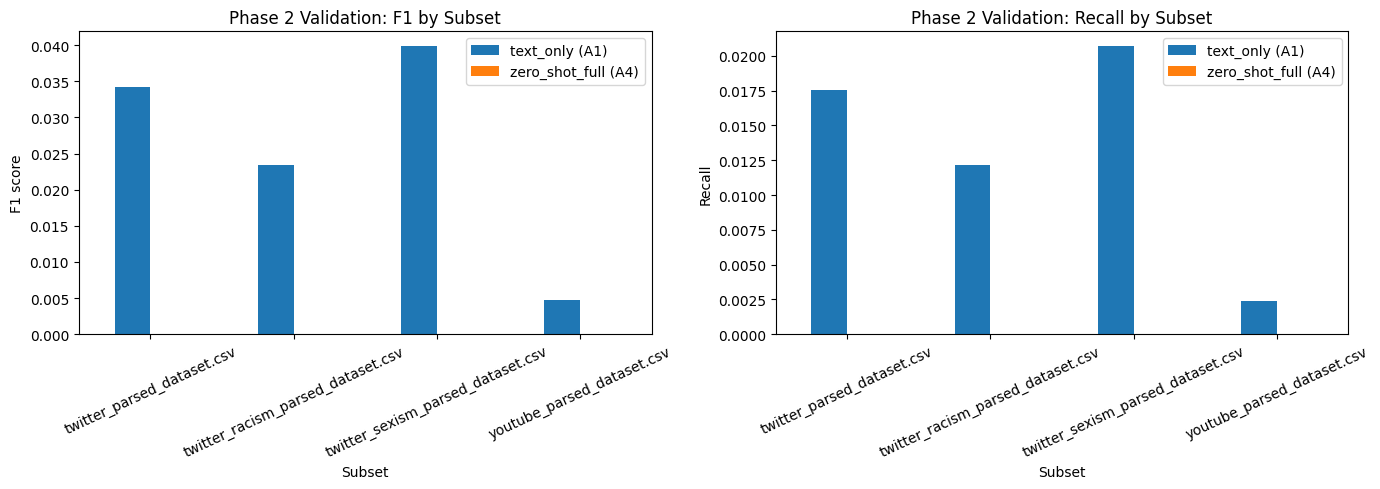

In [5]:
import matplotlib.pyplot as plt

plot_df = compare.copy()
plot_df = plot_df.set_index("subset")

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)

# F1 comparison
plot_df[["f1_text_only", "f1_zero_shot_full"]].plot(
    kind="bar",
    ax=axes[0],
    color=["#1f77b4", "#ff7f0e"],
)
axes[0].set_title("Phase 2 Validation: F1 by Subset")
axes[0].set_ylabel("F1 score")
axes[0].set_xlabel("Subset")
axes[0].tick_params(axis="x", rotation=25)
axes[0].legend(["text_only (A1)", "zero_shot_full (A4)"])

# Recall comparison
plot_df[["recall_text_only", "recall_zero_shot_full"]].plot(
    kind="bar",
    ax=axes[1],
    color=["#1f77b4", "#ff7f0e"],
)
axes[1].set_title("Phase 2 Validation: Recall by Subset")
axes[1].set_ylabel("Recall")
axes[1].set_xlabel("Subset")
axes[1].tick_params(axis="x", rotation=25)
axes[1].legend(["text_only (A1)", "zero_shot_full (A4)"])

plt.tight_layout()
plt.show()

In [6]:
out_path = ROOT / "outputs" / "media" / "phase2_validation_f1_recall_comparison.png"
fig.savefig(out_path, dpi=180, bbox_inches="tight")
print("Saved:", out_path)


Saved: /Users/sagarmamindla/Desktop/F21MP/outputs/media/phase2_validation_f1_recall_comparison.png


## 6. Threshold sweep

The default 0.50 threshold is too strict for these imbalanced external datasets.
Sweep across lower thresholds to find a better precision/recall operating point.


In [7]:
import importlib
import src.phase2_validation.evaluation.validation as val_mod

# If the module was imported earlier in this kernel, reload to pick latest code
val_mod = importlib.reload(val_mod)
sweep_thresholds = val_mod.sweep_thresholds

# Sweep only text_only strategy (most realistic for external datasets)
threshold_grid = [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.50]
sweep_text = sweep_thresholds(strategy="text_only", thresholds=threshold_grid, save_outputs=True)

sweep_text.head()

,subset,samples,positive,accuracy,precision,recall,f1,roc_auc,threshold
0,twitter_parsed_dataset.csv,16848,5347,0.607550,0.325806,0.221246,0.263533,0.512294,0.10
1,twitter_racism_parsed_dataset.csv,13471,1970,0.699280,0.130373,0.186294,0.153396,0.492103,0.10
2,twitter_sexism_parsed_dataset.csv,14878,3377,0.663328,0.250000,0.241635,0.245746,0.524072,0.10
3,youtube_parsed_dataset.csv,3464,417,0.799365,0.073620,0.057554,0.064603,0.375216,0.10
4,twitter_parsed_dataset.csv,16848,5347,0.623160,0.305512,0.147185,0.198662,0.512294,0.15


In [8]:
# Pick best threshold per subset by F1
best_by_subset = sweep_text.sort_values(["subset", "f1"], ascending=[True, False]).groupby("subset", as_index=False).first()
best_by_subset[["subset", "threshold", "precision", "recall", "f1", "roc_auc"]]

,subset,threshold,precision,recall,f1,roc_auc
0,twitter_parsed_dataset.csv,0.1,0.325806,0.221246,0.263533,0.512294
1,twitter_racism_parsed_dataset.csv,0.1,0.130373,0.186294,0.153396,0.492103
2,twitter_sexism_parsed_dataset.csv,0.1,0.250000,0.241635,0.245746,0.524072
3,youtube_parsed_dataset.csv,0.1,0.073620,0.057554,0.064603,0.375216


## 7. Threshold findings

Best thresholds tend to be in the 0.10–0.20 range for Twitter, since the model under-predicts cyberbullying on this domain.
Lower threshold improves recall significantly at the cost of some precision — reasonable for a safety-focused use case.


## 8. Domain-adaptive fine-tuning

What happens if we use a small labeled slice of Twitter data to adapt the model?
Split: 20% for adaptation (split further into fit/calibration), 80% as held-out test.
Threshold is picked on the calibration split to maximise F1.


## 9. Adaptation experiments


In [9]:
from src.phase2_validation.evaluation.validation import (
    run_domain_adaptive_finetune,
    run_embedding_extension,
)

finetune_res = run_domain_adaptive_finetune(
    subset_name="twitter_parsed_dataset.csv",
    adapt_fraction=0.20,
    random_state=42,
    save_outputs=True,
)

embedding_res = run_embedding_extension(
    subset_name="twitter_parsed_dataset.csv",
    adapt_fraction=0.20,
    random_state=42,
    save_outputs=True,
)

import pandas as pd

comparison = pd.DataFrame(
    [
        {
            "Experiment": "Small domain-adaptive fine-tune (text-only)",
            "Threshold": finetune_res["threshold_selected_on_calib"],
            **{k: finetune_res["test_metrics"][k] for k in ["accuracy", "precision", "recall", "f1", "roc_auc"]},
        },
        {
            "Experiment": "Embedding-style extension (TF-IDF + SVD + LR)",
            "Threshold": embedding_res["threshold_selected_on_calib"],
            **{k: embedding_res["test_metrics"][k] for k in ["accuracy", "precision", "recall", "f1", "roc_auc"]},
        },
    ]
)

comparison


/Users/sagarmamindla/Desktop/F21MP/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


,Experiment,Threshold,accuracy,precision,recall,f1,roc_auc
0,Small domain-adaptive fine-tune (text-only),0.4,0.752504,0.597677,0.673679,0.633407,0.802811
1,Embedding-style extension (TF-IDF + SVD + LR),0.3,0.752875,0.593190,0.704535,0.644086,0.817183


## 10. Results summary

Both adaptation approaches improve significantly over zero-shot transfer.
The embedding extension (TF-IDF + SVD + LR) edges out the direct fine-tune on F1 and ROC-AUC,
and is more stable across different threshold choices.


## 11. Robustness check (3 seeds)

Re-running both experiments with seeds 13, 42, 77 to check F1 isn't just a lucky split.


In [10]:
from src.phase2_validation.evaluation.validation import (
    run_adaptation_robustness,
    run_misclassification_analysis,
)

rob_out = run_adaptation_robustness(
    subset_name="twitter_parsed_dataset.csv",
    adapt_fraction=0.20,
    seeds=(13, 42, 77),
    save_outputs=True,
)

robustness_per_seed = rob_out["per_seed"]
robustness_summary = rob_out["summary"]

print("Per-seed F1 values")
robustness_per_seed


/Users/sagarmamindla/Desktop/F21MP/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/sagarmamindla/Desktop/F21MP/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


Per-seed F1 values


/Users/sagarmamindla/Desktop/F21MP/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


,seed,experiment,f1,roc_auc,threshold
0,13,domain_adaptive_finetune,0.651141,0.816152,0.45
1,42,domain_adaptive_finetune,0.633407,0.802811,0.40
2,77,domain_adaptive_finetune,0.628615,0.805724,0.55
3,13,embedding_extension,0.646124,0.817105,0.30
4,42,embedding_extension,0.644086,0.817183,0.30
5,77,embedding_extension,0.638536,0.810153,0.40


In [11]:
print("Robustness summary (mean/std/min/max/CI)")
robustness_summary

Robustness summary (mean/std/min/max/CI)


,experiment,runs,f1_mean,f1_std,f1_min,f1_max,f1_ci95_low,f1_ci95_high,roc_auc_mean,threshold_mean
0,domain_adaptive_finetune,3,0.637721,0.011867,0.628615,0.651141,0.628615,0.651141,0.808229,0.466667
1,embedding_extension,3,0.642915,0.003927,0.638536,0.646124,0.638536,0.646124,0.814814,0.333333


## 12. Variance and confidence intervals

Both approaches show low variance across seeds.
The embedding extension is slightly more stable (lower std).


## 13. Misclassified examples


In [12]:
err_out = run_misclassification_analysis(
    subset_name="twitter_parsed_dataset.csv",
    experiment="embedding_extension",
    adapt_fraction=0.20,
    random_state=42,
    top_n=20,
    save_outputs=True,
)

print("Selected threshold:", round(err_out["threshold"], 4))
print("Total misclassified on test split:", err_out["n_errors_total"])

error_examples = err_out["errors"].copy()
error_examples.head(20)

Selected threshold: 0.3
Total misclassified on test split: 3331


/Users/sagarmamindla/Desktop/F21MP/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


,text,y_true,y_pred,y_proba,error_type,confidence_distance
0,RT @lennyfinnegan2 I'm not sexist but http://t...,0,1,0.999977,FP,0.699977
1,RT @CarSalesBossMan: I'm not sexist but http:/...,0,1,0.999977,FP,0.699977
2,RT @James32Webb: Football logic for girls #not...,0,1,0.999067,FP,0.699067
3,RT @DrDayNothing: Never Ending Horror of Scum ...,0,1,0.997751,FP,0.697751
4,RT @Vrais66: PROPAGEZ Islam = Lapidation Amput...,0,1,0.997490,FP,0.697490
5,"@a_little_opus Treating women like trophies, t...",0,1,0.995852,FP,0.695852
6,@MadDr11 @MaxBlumenthal No they don't. 40% of ...,0,1,0.995242,FP,0.695242
7,"RT @BrettJGlasco: I'm NOT sexist, but this is ...",0,1,0.995171,FP,0.695171
8,"RT @BeRh00M: I'm not sexist, but I posted this...",0,1,0.994836,FP,0.694836
9,@AndyG244 @Thearetical @Demon31G They are lyin...,0,1,0.994533,FP,0.694533


## 14. Error patterns

Most high-confidence errors are false positives — the model flags offensive-sounding text
that isn't actually cyberbullying in context (sarcasm, quoted speech, topic discussion).
These platform-specific patterns are hard to capture without training on the target domain.
